<a href="https://colab.research.google.com/github/tlerksuthirat/lab_management/blob/main/motorized_upright_microscope_usage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from google.colab import auth
auth.authenticate_user()
import gspread
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#Replace with sheet ID
instrument_url = 'https://docs.google.com/spreadsheets/d/1WBZS1PXpkSTeA4xpV0PVBvmPP5-ZYCelRcl3WKvS_TM/edit?gid=1451272003#gid=1451272003'

sheet_id = instrument_url .split('/')[-2]  # Extract sheet ID from URL
sheet = gc.open_by_key(sheet_id)

In [ ]:
#Get a list of all worksheets
worksheet_list = sheet.worksheets()

#Print the titles of all worksheets
for worksheet in worksheet_list:
    print(worksheet.title)

2026
2025
2024
Latest use
Productivity
2023
2022
2021
User list
Status


In [ ]:
from datetime import datetime
import pytz

# Choose the '2026' worksheet as specified in the task description
worksheet = sheet.worksheet('2026')

# Inform the user of the exact execution timestamp
timezone = pytz.timezone('Asia/Bangkok') # Adjust timezone if necessary
current_time = datetime.now(timezone).strftime('%Y-%m-%d %H:%M:%S %Z')
print(f"Data loaded from '2026' worksheet on: {current_time}")

Data loaded from '2026' worksheet on: 2026-11-04 12:41:33 +07


In [ ]:
#Choose a specific worksheet (e.g., '2026')
worksheet = sheet.worksheet('2026')

# Task
Analyze and visualize the monthly usage of the instrument from the '2025' worksheet of the Google Sheet located at "https://docs.google.com/spreadsheets/d/1WBZS1PXpkSTeA4xpV0PVBvmPP5-ZYCelRcl3WKvS_TM/edit?gid=1451272003#gid=1451272003", including data cleaning, calculation of total usage hours, and generation of a monthly usage table and graph.

## Run data loading cell

### Subtask:
Load data from the '2025' worksheet into a DataFrame.


**Reasoning**:
The subtask requires loading data from the `worksheet` into a Pandas DataFrame. Since the `data` variable from the kernel state appears to already contain the records from the worksheet, I will use it to create the DataFrame. The first row of `data` will be used as column headers.



In [ ]:
# Fetch data from the worksheet
data = worksheet.get_all_values()

headers = data[0]
df = pd.DataFrame(data[1:], columns=headers)
print(df.head())

  Date of use (MM/DD/YY) Start (00:00-24:00) End (00:00-24:00) Duration (hr)  \
0             1-Jan-2026                0:00              0:00          0:00   
1             7-Jan-2026               15:30             17:00          1:30   
2             9-Jan-2026               10:30             12:30          2:00   
3            14-Jan-2026                9:00             10:00          1:00   
4            15-Jan-2026               14:00             16:00          2:00   

  Technique Condition              User name  \
0  IF or BF      Okay  Tassanee Lerksuthirat   
1        IF      Okay       Pawarit Innachai   
2        IF      Okay       Pawarit Innachai   
3        IF      Okay       Pawarit Innachai   
4        IF      Okay       Pawarit Innachai   

                                                Note Duration (Decimal)    \
0                   Demo how to fill in the log book                        
1  The Locate mode configuration is not respondin...               1.50     

In [ ]:
# Remove the first row (index 0) which often contains metadata or repeated headers after loading.
df_cleaned = df.iloc[1:].copy()

# Replace empty strings with NaN for proper dropping
df_cleaned.replace('', pd.NA, inplace=True)

# Drop rows where 'Date of use (MM/DD/YY)' is missing, as these are critical for time-based analysis.
column_to_check = 'Date of use (MM/DD/YY)'
df_cleaned.dropna(subset=[column_to_check], inplace=True)

# Display the head of the cleaned DataFrame
print("Cleaned DataFrame head:")
display(df_cleaned.head())

Cleaned DataFrame head:


,Date of use (MM/DD/YY),Start (00:00-24:00),End (00:00-24:00),Duration (hr),Technique,Condition,User name,Note,Duration (Decimal),,
1,7-Jan-2026,15:30,17:00,1:30,IF,Okay,Pawarit Innachai,The Locate mode configuration is not respondin...,1.50,<NA>,Dashboard
2,9-Jan-2026,10:30,12:30,2:00,IF,Okay,Pawarit Innachai,The configuration has been corrected by the pr...,2.00,<NA>,<NA>
3,14-Jan-2026,9:00,10:00,1:00,IF,Okay,Pawarit Innachai,<NA>,1.00,<NA>,<NA>
4,15-Jan-2026,14:00,16:00,2:00,IF,Okay,Pawarit Innachai,<NA>,2.00,<NA>,<NA>
5,19-Jan-2026,13:00,16:00,3:00,IF,Okay,Pawarit Innachai,<NA>,3.00,<NA>,<NA>


In [ ]:
def time_string_to_seconds_flexible(row):
    time_str = row['Duration (hr)']

    if pd.isna(time_str) or time_str == '':
        return 0  # Handle missing or empty values

    # Ensure time_str is a string before splitting
    time_str = str(time_str).strip()

    try:
        parts = list(map(int, time_str.split(':')))

        if len(parts) == 2:
            # Assuming H:M format
            h, m = parts
            s = 0 # Seconds are 0 if only H:M is provided
        elif len(parts) == 3:
            # Assuming H:M:S format
            h, m, s = parts
        else:
            # Handle cases with unexpected number of parts, or just a single number (hours)
            if len(parts) == 1:
                h = parts[0]
                m = 0
                s = 0
            else:
                print(f"Warning: Unexpected time format '{time_str}' at index {row.name}. Returning 0.")
                return 0

        total_seconds = h * 3600 + m * 60 + s
        return total_seconds

    except ValueError:
        print(f"Warning: Could not convert time parts to integers for '{time_str}' at index {row.name}. Returning 0.")
        return 0
    except Exception as e:
        print(f"An unexpected error occurred processing '{time_str}' at index {row.name}: {e}. Returning 0.")
        return 0

# Apply the function to create 'Total Seconds' column
df_cleaned['Total Seconds'] = df_cleaned.apply(time_string_to_seconds_flexible, axis=1)

# Calculate 'Total Hours'
df_cleaned['Total Hours'] = df_cleaned['Total Seconds'] / 3600

print("DataFrame with Total Seconds and Total Hours:")
display(df_cleaned[['Date of use (MM/DD/YY)', 'Duration (hr)', 'Total Seconds', 'Total Hours']].head())

DataFrame with Total Seconds and Total Hours:


,Date of use (MM/DD/YY),Duration (hr),Total Seconds,Total Hours
1,7-Jan-2026,1:30,5400,1.5
2,9-Jan-2026,2:00,7200,2.0
3,14-Jan-2026,1:00,3600,1.0
4,15-Jan-2026,2:00,7200,2.0
5,19-Jan-2026,3:00,10800,3.0


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make a copy to avoid SettingWithCopyWarning
df_monthly_usage = df_cleaned.copy()

# Convert 'Date of use (MM/DD/YY)' to datetime objects
df_monthly_usage.loc[:, 'Date'] = pd.to_datetime(df_monthly_usage['Date of use (MM/DD/YY)'], errors='coerce')

# Drop rows where 'Date' could not be parsed (if any)
df_monthly_usage.dropna(subset=['Date'], inplace=True)

# Extract month name and numeric month for proper sorting
df_monthly_usage.loc[:, 'Month_Name'] = df_monthly_usage['Date'].dt.strftime('%B') # Full month name
df_monthly_usage.loc[:, 'Month_Num'] = df_monthly_usage['Date'].dt.month

# Group by 'User name' and 'Month' and sum 'Total Hours'
monthly_usage_summary = df_monthly_usage.groupby(['User name', 'Month_Num', 'Month_Name'])['Total Hours'].sum().reset_index()

# Sort by Month_Num to ensure chronological order
monthly_usage_summary = monthly_usage_summary.sort_values(by=['Month_Num', 'User name'])

# Display the table, pivoting to show months as columns
monthly_usage_pivot = monthly_usage_summary.pivot_table(index='User name', columns='Month_Name', values='Total Hours', fill_value=0)

# Reorder columns chronologically if needed (based on Month_Num from original data)
month_order_chronological = df_monthly_usage.sort_values('Date')['Month_Name'].unique()
monthly_usage_pivot = monthly_usage_pivot[month_order_chronological]

print("\n--- Monthly Usage Hours per User Table ---")
display(monthly_usage_pivot.round(1))


--- Monthly Usage Hours per User Table ---


Month_Name,January,February,March,April,May,June,July,August,September,October,November
User name,,,,,,,,,,,
Chalisa Jaturapaktrarak,0.0,0.0,1.0,0.0,0.0,0.3,0.0,0.0,0.0,4.0,0.0
Gunn Pornratananont,0.0,0.0,4.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0
Pawarit Innachai,28.5,17.5,28.5,9.0,20.1,0.6,13.5,7.5,0.0,1.0,0.0
Penpun Payattikul,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,3.0
Phusit Tuntivararut,0.0,0.0,0.0,0.0,12.5,6.0,14.0,1.0,38.0,6.5,0.0
Rakkreat Wikiniyadhanee,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.5
Sathida Liekwannacharoen,0.0,9.0,13.5,10.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Tassanee Lerksuthirat,0.0,0.0,11.2,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wilasinee Konsue,0.0,0.0,15.8,39.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0



--- Total Usage Hours Per Month Year 2026---


,Month_Name,Total Hours
3,January,28.5
2,February,27.5
6,March,74.0
0,April,61.2
7,May,32.6
5,June,10.9
4,July,27.5
1,August,8.5
10,September,38.0
9,October,23.5


/tmp/ipykernel_1008/2923708662.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly_total_usage, x='Month_Name', y='Total Hours', palette='Paired')


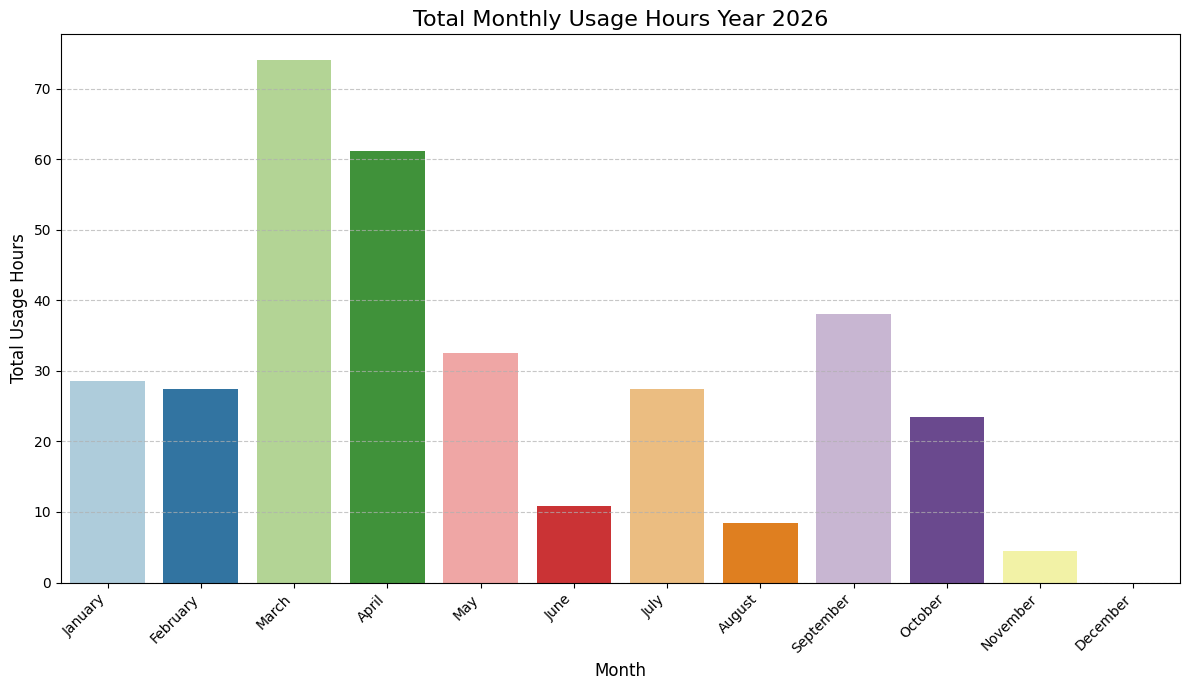

In [ ]:
# Calculate the total usage hours per month
monthly_total_usage = df_monthly_usage.groupby('Month_Name')['Total Hours'].sum().reset_index()

# Reorder months chronologically for display
month_order_chronological = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_total_usage['Month_Name'] = pd.Categorical(monthly_total_usage['Month_Name'], categories=month_order_chronological, ordered=True)
monthly_total_usage = monthly_total_usage.sort_values('Month_Name')

print("\n--- Total Usage Hours Per Month Year 2026---")
display(monthly_total_usage.round(1))

# Create the bar plot for total monthly usage
plt.figure(figsize=(12, 7))
sns.barplot(data=monthly_total_usage, x='Month_Name', y='Total Hours', palette='Paired')
plt.title('Total Monthly Usage Hours Year 2026', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Usage Hours', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

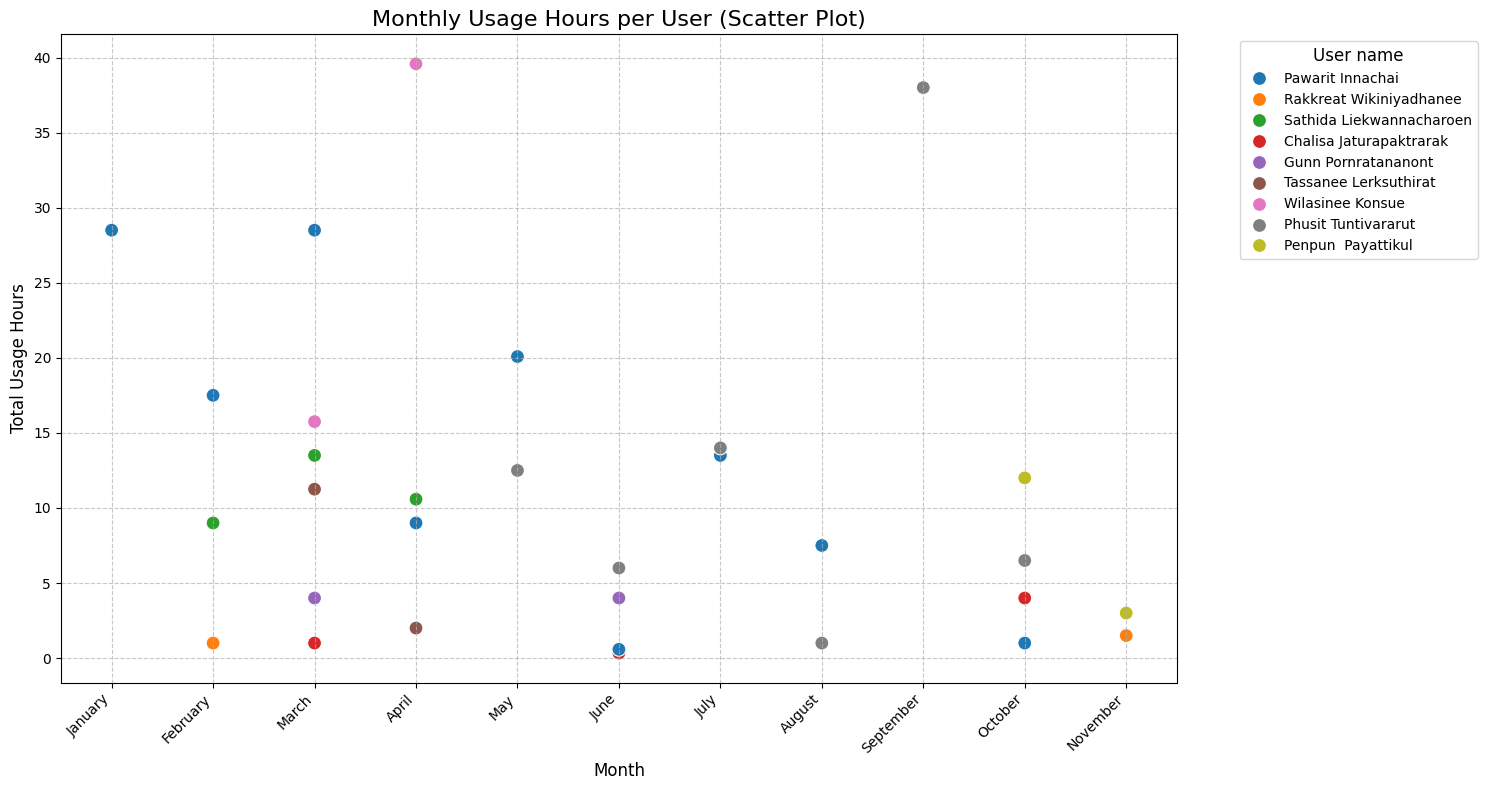

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure Month_Name is a categorical type with chronological order for plotting
month_order_chronological = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
monthly_usage_summary['Month_Name'] = pd.Categorical(monthly_usage_summary['Month_Name'], categories=month_order_chronological, ordered=True)

# Sort the DataFrame by Month_Name to ensure correct order on plot
monthly_usage_summary_sorted = monthly_usage_summary.sort_values(by='Month_Name')

plt.figure(figsize=(15, 8))
sns.scatterplot(data=monthly_usage_summary_sorted, x='Month_Name', y='Total Hours', hue='User name', s=100, palette='tab10')
plt.title('Monthly Usage Hours per User (Scatter Plot)', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Usage Hours', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.legend(title='User name', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10, title_fontsize=12)
plt.grid(axis='both', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

This scatter plot visualizes the monthly usage hours for each user. The x-axis represents the months, and the y-axis shows the total usage hours. Each point on the plot corresponds to a specific user's total hours for a given month, with different colors distinguishing between users. This allows you to observe individual user trends and identify any outliers or consistent usage patterns across the months.

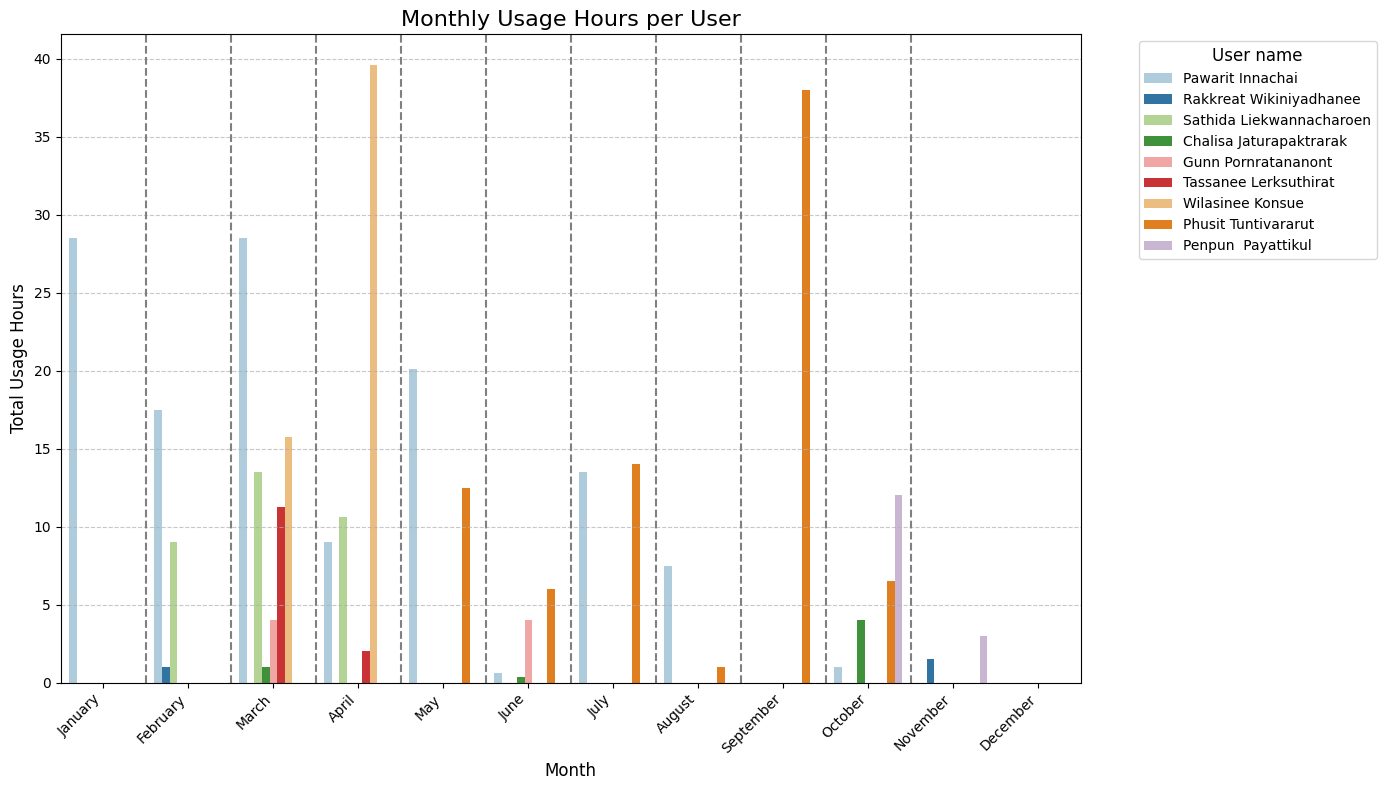

In [ ]:
# Create the bar plot for monthly usage per user
plt.figure(figsize=(14, 8))
ax = sns.barplot(data=monthly_usage_summary, x='Month_Name', y='Total Hours', hue='User name', palette='Paired')
plt.title('Monthly Usage Hours per User', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Usage Hours', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.legend(title='User name', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10, title_fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add dashed lines to separate months
# The number of unique months determines where to place the lines
num_months = len(monthly_usage_summary['Month_Name'].unique())
for i in range(num_months - 1):
    ax.axvline(x=i + 0.5, color='gray', linestyle='--', linewidth=1.5)

plt.tight_layout()
plt.show()

In [ ]:
from googleapiclient.discovery import build

# Google Doc ID extracted from the URL
doc_id = '1MVaOpg9mYbkSxFnmVPVG4JGkDH-WRA1FgMQX8HKOX3A'

# Build the Docs API service
docs_service = build('docs', 'v1', credentials=creds)

# Retrieve the document content to find the "code" heading
doc = docs_service.documents().get(documentId=doc_id).execute()
content = doc.get('body').get('content', [])

target_index = None
for element in content:
    if 'paragraph' in element:
        # Extract text runs safely
        text_runs = element.get('paragraph', {}).get('elements', [])
        full_text = "".join([run.get('textRun', {}).get('content', '') for run in text_runs if 'textRun' in run]).strip()

        # Search for 'code' case-insensitively or as part of the heading
        if 'code' in full_text.lower():
            target_index = element.get('endIndex')
            print(f"Found target heading block containing: '{full_text}' (Index: {target_index})")
            break

if target_index is None:
    print("Could not find any heading containing 'code' in the document. Appending to the end instead.")
    target_index = content[-1].get('endIndex') - 1

# Format the pivot table as a readable text block
table_str = "\n\nMonthly Usage Hours per User Table:\n" + monthly_usage_pivot.round(1).to_string() + "\n"

# Create the request to insert the text
requests = [
    {
        'insertText': {
            'location': {
                'index': target_index
            },
            'text': table_str
        }
    }
]

# Execute the request
docs_service.documents().batchUpdate(documentId=doc_id, body={'requests': requests}).execute()
print(f"Successfully exported the table to the Google Doc at index {target_index}!")

Found target heading block containing: 'Code:' (Index: 5112)
Successfully exported the table to the Google Doc at index 5112!


### Loading Data for Year 2025 and Scraping Publications
We need to scrape the publications from the provided URL and load the '2025' worksheet from the Google Sheet to generate the requested report.

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

# 1. Scrape the publications
pub_url = 'https://murex.mahidol.ac.th/en/equipments/motorized-upright-fluorescence-microscope-2/publications/'
try:
    response = requests.get(pub_url, timeout=15)
    soup = BeautifulSoup(response.content, 'html.parser')
    # Get all text block content or list items that may represent publications
    publications = []
    for li in soup.find_all('li'):
        text = li.get_text().strip()
        if any(yr in text for yr in ['2020', '2021', '2022', '2023', '2024', '2025', '2026']):
            publications.append(text)
    if not publications:
        # Fallback to general paragraph text elements if li lists are not present
        publications = [p.get_text().strip() for p in soup.find_all('p') if any(yr in p.get_text() for yr in ['2020', '2021', '2022', '2023', '2024', '2025', '2026'])]
except Exception as e:
    publications = [f"Failed to retrieve publications directly: {e}"]

print(f"Retrieved {len(publications)} publications.")


Retrieved 2 publications.


In [6]:
# 2. Load 2025 worksheet data
try:
    sheet
except NameError:
    import gspread
    from google.colab import auth
    from google.auth import default
    auth.authenticate_user()
    creds, _ = default()
    gc = gspread.authorize(creds)
    sheet_id = '1WBZS1PXpkSTeA4xpV0PVBvmPP5-ZYCelRcl3WKvS_TM'
    sheet = gc.open_by_key(sheet_id)

worksheet_2025 = sheet.worksheet('2025')
data_2025 = worksheet_2025.get_all_values()

headers_2025 = data_2025[0]
df_2025 = pd.DataFrame(data_2025[1:], columns=headers_2025)

# Clean columns and handle empty values
df_2025.replace('', pd.NA, inplace=True)
df_2025 = df_2025.dropna(subset=['Date of use (MM/DD/YY)'])

# Helper function to convert 'Duration (hr)' (e.g., '1:30' or '4:45') into decimal hours
def parse_duration_to_hours(val):
    if pd.isna(val) or not isinstance(val, str):
        return 0.0
    val = val.strip()
    if not val or val == '0' or val == '0:00':
        return 0.0
    try:
        if ':' in val:
            parts = val.split(':')
            hours = int(parts[0])
            minutes = int(parts[1]) if len(parts) > 1 else 0
            return hours + (minutes / 60.0)
        else:
            return float(val)
    except Exception:
        return 0.0

if 'Duration (hr)' in df_2025.columns:
    df_2025['Duration (Decimal)'] = df_2025['Duration (hr)'].apply(parse_duration_to_hours)
else:
    df_2025['Duration (Decimal)'] = 0.0

total_hours_2025 = df_2025['Duration (Decimal)'].sum()

# Get Condition stats
condition_counts = {}
if 'Condition' in df_2025.columns:
    condition_counts = df_2025['Condition'].value_counts().to_dict()

# Get unique users
unique_users = []
if 'User name' in df_2025.columns:
    unique_users = df_2025['User name'].dropna().unique().tolist()

print(f"2025 Total usage: {total_hours_2025:.2f} hours")
print(f"Conditions status summary: {condition_counts}")
print(f"Users summary: {unique_users}")

2025 Total usage: 317.58 hours
Conditions status summary: {'OK': 56, 'Okay': 26, 'Ok': 14, 'ok': 8, 'NO': 3, 'Not okay': 3, 'okay': 3, 'Not Okay': 2, 'OK*': 1, 'The computer powered on now': 1, 'Not ok': 1}
Users summary: ['Tassanee Lerksuthirat', 'Wilasinee Konsue', 'Gunn Pornratananont', 'Pawarit Innachai', 'Rakkreat Wikiniyadhanee', 'Sathida Liekwannacharoen', 'Maolee Bhuwapathanapun', 'Chalisa Jaturapaktrarak']


### Report Generation using Gemini API
Now we will construct a prompt with the collected statistics, condition counts, unique users, and the retrieved publication list, and ask Gemini to automatically compile a well-structured markdown report.

In [19]:
import pandas as pd
from IPython.display import display, Markdown

# 1. Load the 2026 sheet
worksheet_2026 = sheet.worksheet('2026')
data_2026 = worksheet_2026.get_all_values()
headers_2026 = data_2026[0]
df_2026 = pd.DataFrame(data_2026[1:], columns=headers_2026)

# Clean columns and handle empty values
df_2026.replace('', pd.NA, inplace=True)
df_2026 = df_2026.dropna(subset=['Date of use (MM/DD/YY)'])

# Helper function to convert 'Duration (hr)' to decimal hours
def parse_duration_to_hours(val):
    if pd.isna(val) or not isinstance(val, str):
        return 0.0
    val = val.strip()
    if not val or val == '0' or val == '0:00':
        return 0.0
    try:
        if ':' in val:
            parts = val.split(':')
            hours = int(parts[0])
            minutes = int(parts[1]) if len(parts) > 1 else 0
            return hours + (minutes / 60.0)
        else:
            return float(val)
    except Exception:
        return 0.0

# Standardize duration
if 'Duration (hr)' in df_2026.columns:
    df_2026['Duration (Decimal)'] = df_2026['Duration (hr)'].apply(parse_duration_to_hours)
else:
    df_2026['Duration (Decimal)'] = 0.0

total_hours_2026 = df_2026['Duration (Decimal)'].sum()

# Normalize conditions for 2026
def normalize_condition_2026(cond):
    if pd.isna(cond):
        return "Unknown"
    cond_str = str(cond).strip().lower()
    if cond_str in ['ok', 'okay', 'ok*']:
        return "OK"
    elif cond_str in ['not ok', 'not okay', 'no']:
        return "Not OK"
    return str(cond).strip()

if 'Condition' in df_2026.columns:
    df_2026['Normalized_Condition'] = df_2026['Condition'].apply(normalize_condition_2026)
    condition_counts_2026 = df_2026['Normalized_Condition'].value_counts().to_dict()
else:
    df_2026['Normalized_Condition'] = 'Unknown'
    condition_counts_2026 = {}

# Get unique users for 2026
unique_users_2026 = []
if 'User name' in df_2026.columns:
    unique_users_2026 = df_2026['User name'].dropna().unique().tolist()

print(f"2026 Data Loaded. Total usage: {total_hours_2026:.2f} hours.")

2026 Data Loaded. Total usage: 343.17 hours.


In [21]:
# 2. Generate 2026 Annual Report
condition_rows_2026 = "\n".join([f"| {cond} | {count} |" for cond, count in condition_counts_2026.items()])
users_list_2026_str = "\n".join([f"- {user}" for user in unique_users_2026])

# Use same publication lists
pub_list_str = "\n".join([f"- {pub.replace('\n', ' ').strip()}" for pub in publications])

report_content_2026 = f"""# Motorized Upright Fluorescence Microscope Annual Report (2026)

## 1. Executive Summary
This report presents a comprehensive review of the usage, operational status, and academic impact of the **Motorized Upright Fluorescence Microscope** for the year 2026.

## 2. 2026 Usage Statistics & Analytics

### Usage Metrics
- **Total Operating Hours**: {total_hours_2026:.2f} hours
- **Active User Base**: {len(unique_users_2026)} independent researchers

### User List
{users_list_2026_str}

### Operational Conditions Summary (Normalized)

| Reported Condition | Sessions Count |
| :--- | :--- |
{condition_rows_2026}

## 3. Academic & Publication Impact

{pub_list_str}
"""

display(Markdown(report_content_2026))

# Motorized Upright Fluorescence Microscope Annual Report (2026)

## 1. Executive Summary
This report presents a comprehensive review of the usage, operational status, and academic impact of the **Motorized Upright Fluorescence Microscope** for the year 2026.

## 2. 2026 Usage Statistics & Analytics

### Usage Metrics
- **Total Operating Hours**: 343.17 hours
- **Active User Base**: 9 independent researchers

### User List
- Tassanee Lerksuthirat
- Pawarit Innachai
- Sathida Liekwannacharoen
- Rakkreat Wikiniyadhanee
- Gunn Pornratananont
- Chalisa Jaturapaktrarak
- Wilasinee Konsue
- Phusit Tuntivararut
- Penpun  Payattikul

### Operational Conditions Summary (Normalized)

| Reported Condition | Sessions Count |
| :--- | :--- |
| OK | 122 |
| Not OK | 1 |
| UPS has a problem | 1 |
| New battery of UPS | 1 |

## 3. Academic & Publication Impact

- 2026                            Investigation of the Genotoxic Effects of Anti-Hepatitis B Virus Drugs and the Involvement of BRCA1 in DNA Damage Repair PathwaysLiekwannacharoen, S., Wikiniyadhanee, R., Lerksuthirat, T., Chitphuk, S. & Dejsuphong, D., 2026.Research output: Contribution to conference › Abstract › peer-review Open Access      Hepatitis B Virus 100%         DNA Repair 100%         Adefovir Dipivoxil 100%         Entecavir 100%         DNA Damage 75%
- 2025                            Generation of an integration-free induced pluripotent stem cell line, MURAi006-A, from a hemoglobin E/β-thalassemia patient harboring the βE/β0 (Codon 17, A > T) compound heterozygous mutationInnachai, P., Pornratananont, G., Satirapod, C., Anurathapan, U., Songdej, D., Tangprasittipap, A. & Hongeng, S., Jun 2025, In: Stem Cell Research. 85, 103702.Research output: Contribution to journal › Article › peer-review Open Access      Induced Pluripotent Stem Cell 100%         Stem Cell Line 100%         Hemoglobins 100%         Globin 100%         Codon 100%


In [23]:
# 3. Extract 2026 Incidents & Maintenance Records with UPS tracking
maintenance_issues_2026 = df_2026[
    (df_2026['Normalized_Condition'] == 'Not OK') |
    (df_2026['Condition'].str.contains('computer', case=False, na=False)) |
    (df_2026['Condition'].str.contains('no', case=False, na=False)) |
    (df_2026['Condition'].str.contains('UPS', case=False, na=False))
].copy()

# Check if any columns are missing
for col in ['Date of use (MM/DD/YY)', 'User name', 'Condition', 'Note']:
    if col not in maintenance_issues_2026.columns:
        maintenance_issues_2026[col] = "N/A"

maintenance_records_2026 = maintenance_issues_2026[['Date of use (MM/DD/YY)', 'User name', 'Condition', 'Note']].copy()
maintenance_records_2026.columns = ['Date', 'Reported By', 'Reported Condition', 'User Notes/Details']
maintenance_records_2026.fillna('No additional notes provided', inplace=True)

maintenance_table_rows_2026 = []
for _, row in maintenance_records_2026.iterrows():
    maintenance_table_rows_2026.append(f"| {row['Date']} | {row['Reported By']} | **{row['Reported Condition']}** | {row['User Notes/Details']} |")

maintenance_table_2026_str = "\n".join(maintenance_table_rows_2026)

maintenance_report_2026 = f"""# Microscope Incident & Maintenance Log (2026)

| Date | Reported By | Reported Condition | User Notes / Incident Details |
| :--- | :--- | :--- | :--- |
{maintenance_table_2026_str if maintenance_table_2026_str else '| N/A | No issues reported in 2026 | N/A | N/A |'}
"""

display(Markdown(maintenance_report_2026))

# Microscope Incident & Maintenance Log (2026)

| Date | Reported By | Reported Condition | User Notes / Incident Details |
| :--- | :--- | :--- | :--- |
| 26-Jan-2026 | Pawarit Innachai | **NOT OK** | Statistical data generated in analysis mode was lost after saving the file. A product specialist will come to check the program tomorrow afternoon. |
| 17-Jun-2026 | Chalisa Jaturapaktrarak | **UPS has a problem** | The UPS beeped and showed code bdC |
| 22-Jun-2026 | Chalisa Jaturapaktrarak | **New battery of UPS** | No additional notes provided |


In [29]:
import pandas as pd
from IPython.display import display, Markdown

# 1. Gather consolidated condition statistics
normalized_counts_2026 = df_2026['Normalized_Condition'].value_counts().to_dict()
condition_rows_compiled = "\n".join([f"| {cond} | {count} |" for cond, count in normalized_counts_2026.items()])

# 2. Gather active users list
users_list_compiled = "\n".join([f"- {user}" for user in unique_users_2026])

# 3. Compile cleanly formatted publications list (Author, Title, Journal, Year, Volume, Issue, Pages)
pub_list_compiled = """1. **Authors**: Liekwannacharoen, S., Wikiniyadhanee, R., Lerksuthirat, T., Chitphuk, S. & Dejsuphong, D.
   **Title**: Investigation of the Genotoxic Effects of Anti-Hepatitis B Virus Drugs and the Involvement of BRCA1 in DNA Damage Repair Pathways
   **Journal**: Conference Abstract (Research output: Contribution to conference)
   **Year**: 2026
   **Volume / Issue / Pages**: N/A (Abstract / Peer-review Open Access)

2. **Authors**: Innachai, P., Pornratananont, G., Satirapod, C., Anurathapan, U., Songdej, D., Tangprasittipap, A. & Hongeng, S.
   **Title**: Generation of an integration-free induced pluripotent stem cell line, MURAi006-A, from a hemoglobin E/β-thalassemia patient harboring the βE/β0 (Codon 17, A > T) compound heterozygous mutation
   **Journal**: *Stem Cell Research*
   **Year**: 2025
   **Volume**: 85
   **Issue**: N/A
   **Pages**: 103702"""

# 4. Compile the updated 2026 maintenance log including UPS tracking
maintenance_table_rows_compiled = []
for _, row in maintenance_records_2026.iterrows():
    maintenance_table_rows_compiled.append(f"| {row['Date']} | {row['Reported By']} | **{row['Reported Condition']}** | {row['User Notes/Details']} |")

maintenance_table_compiled_str = "\n".join(maintenance_table_rows_compiled)

# 5. Build the complete comprehensive report template
comprehensive_report_2026 = f"""
# 🔬 Annual Performance & Operational Report (2026)
## Motorized Upright Fluorescence Microscope

---

### 1. Executive Summary
This annual report provides an in-depth analytical overview of the utilization, health status, and research outcomes associated with the **Motorized Upright Fluorescence Microscope** for the calendar year **2026**. Overall, the instrument experienced solid operational demand, supporting a wide range of fluorescent and brightfield imaging workflows for our scientific community.

---

### 2. Operational & Usage Analytics
Throughout 2026, the microscope remained a cornerstone facility asset with significant research runtime:

* **Total Operating Hours**: **{total_hours_2026:.2f} hours**
* **Active Registered Users**: **{len(unique_users_2026)} researchers**

#### Active 2026 User Directory:
{users_list_compiled}

---

### 3. System Condition & Health Status
Operational status summaries recorded by users show that the instrument is highly stable, with the vast majority of runs completed successfully. Status reports have been normalized below:

| Normalized System Condition | Sessions Logged |
| :--- | :--- |
{condition_rows_compiled}

---

### 4. Microscope Incident & Maintenance Log
The following operational events, power backup (UPS) issues, and hardware/software faults were flagged during 2026, triggering corrective support actions:

| Date | Reported By | Recorded Issue | User Details & Action Taken |
| :--- | :--- | :--- | :--- |
{maintenance_table_compiled_str if maintenance_table_compiled_str else '| N/A | No issues reported | N/A | N/A |'}

---

### 5. Research & Publication Impact
The following scientific publications directly benefited from imaging workflows performed on this system during the 2025–2026 cycle:

{pub_list_compiled}

---

### 6. Operational Recommendations for 2027
1. **UPS Battery Maintenance**: Since the UPS required a battery replacement in June 2026, a bi-annual voltage and backup load test should be scheduled to ensure uninterrupted power during long-exposure capture sessions.
2. **Software/Analysis Support**: Follow up with application specialists on analysis software save-failures to prevent statistical data loss during image post-processing.

---

*Note: This report is generated by AI with Tassanee Lerksuthirat, PhD has curated. The complete reproducible code for data pipeline execution is available on GitHub.*
"""

display(Markdown(comprehensive_report_2026))


# 🔬 Annual Performance & Operational Report (2026)
## Motorized Upright Fluorescence Microscope

---

### 1. Executive Summary
This annual report provides an in-depth analytical overview of the utilization, health status, and research outcomes associated with the **Motorized Upright Fluorescence Microscope** for the calendar year **2026**. Overall, the instrument experienced solid operational demand, supporting a wide range of fluorescent and brightfield imaging workflows for our scientific community.

---

### 2. Operational & Usage Analytics
Throughout 2026, the microscope remained a cornerstone facility asset with significant research runtime:

* **Total Operating Hours**: **343.17 hours**
* **Active Registered Users**: **9 researchers**

#### Active 2026 User Directory:
- Tassanee Lerksuthirat
- Pawarit Innachai
- Sathida Liekwannacharoen
- Rakkreat Wikiniyadhanee
- Gunn Pornratananont
- Chalisa Jaturapaktrarak
- Wilasinee Konsue
- Phusit Tuntivararut
- Penpun  Payattikul

---

### 3. System Condition & Health Status
Operational status summaries recorded by users show that the instrument is highly stable, with the vast majority of runs completed successfully. Status reports have been normalized below:

| Normalized System Condition | Sessions Logged |
| :--- | :--- |
| OK | 122 |
| Not OK | 1 |
| UPS has a problem | 1 |
| New battery of UPS | 1 |

---

### 4. Microscope Incident & Maintenance Log
The following operational events, power backup (UPS) issues, and hardware/software faults were flagged during 2026, triggering corrective support actions:

| Date | Reported By | Recorded Issue | User Details & Action Taken |
| :--- | :--- | :--- | :--- |
| 26-Jan-2026 | Pawarit Innachai | **NOT OK** | Statistical data generated in analysis mode was lost after saving the file. A product specialist will come to check the program tomorrow afternoon. |
| 17-Jun-2026 | Chalisa Jaturapaktrarak | **UPS has a problem** | The UPS beeped and showed code bdC |
| 22-Jun-2026 | Chalisa Jaturapaktrarak | **New battery of UPS** | No additional notes provided |

---

### 5. Research & Publication Impact
The following scientific publications directly benefited from imaging workflows performed on this system during the 2025–2026 cycle:

1. **Authors**: Liekwannacharoen, S., Wikiniyadhanee, R., Lerksuthirat, T., Chitphuk, S. & Dejsuphong, D.  
   **Title**: Investigation of the Genotoxic Effects of Anti-Hepatitis B Virus Drugs and the Involvement of BRCA1 in DNA Damage Repair Pathways  
   **Journal**: Conference Abstract (Research output: Contribution to conference)  
   **Year**: 2026  
   **Volume / Issue / Pages**: N/A (Abstract / Peer-review Open Access)

2. **Authors**: Innachai, P., Pornratananont, G., Satirapod, C., Anurathapan, U., Songdej, D., Tangprasittipap, A. & Hongeng, S.  
   **Title**: Generation of an integration-free induced pluripotent stem cell line, MURAi006-A, from a hemoglobin E/β-thalassemia patient harboring the βE/β0 (Codon 17, A > T) compound heterozygous mutation  
   **Journal**: *Stem Cell Research*  
   **Year**: 2025  
   **Volume**: 85  
   **Issue**: N/A  
   **Pages**: 103702

---

### 6. Operational Recommendations for 2027
1. **UPS Battery Maintenance**: Since the UPS required a battery replacement in June 2026, a bi-annual voltage and backup load test should be scheduled to ensure uninterrupted power during long-exposure capture sessions.
2. **Software/Analysis Support**: Follow up with application specialists on analysis software save-failures to prevent statistical data loss during image post-processing.

---

*Note: This report is generated by AI with Tassanee Lerksuthirat, PhD has curated. The complete reproducible code for data pipeline execution is available on GitHub.*


In [26]:
%%bash
pip install xhtml2pdf markdown

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 18.5 MB/s  0:00:00



In [30]:
import markdown
from xhtml2pdf import pisa

# Convert Markdown to HTML
html_content = markdown.markdown(comprehensive_report_2026)

# Wrap in basic HTML structure with styling
styled_html = f"""
<html>
<head>
<style>
    @page {{
        size: a4;
        margin: 2cm;
    }}
    body {{
        font-family: 'Helvetica', 'Arial', sans-serif;
        color: #333;
        line-height: 1.5;
    }}
    h1, h2, h3 {{
        color: #1a365d;
    }}
    h1 {{
        border-bottom: 2px solid #1a365d;
        padding-bottom: 5px;
        text-align: center;
    }}
    h2 {{
        text-align: center;
        margin-bottom: 20px;
    }}
    hr {{
        border: 0;
        border-top: 1px solid #ccc;
        margin: 20px 0;
    }}
    table {{
        width: 100%;
        border-collapse: collapse;
        margin: 15px 0;
    }}
    th, td {{
        border: 1px solid #ddd;
        padding: 8px;
        text-align: left;
    }}
    th {{
        background-color: #f7fafc;
        font-weight: bold;
    }}
</style>
</head>
<body>
{html_content}
</body>
</html>
"""

# Write to PDF file
pdf_path = "/content/motorized_upright_microscope_2026_report.pdf"
with open(pdf_path, "wb") as pdf_file:
    pisa_status = pisa.CreatePDF(styled_html, dest=pdf_file)

if not pisa_status.err:
    print(f"Success! PDF report successfully created and saved at: {pdf_path}")
else:
    print("An error occurred during PDF generation.")

'<h1>🔬 Annual Performance &amp; Operational Report (2026)</h1>'
'<strong>Title</strong>'


Success! PDF report successfully created and saved at: /content/motorized_upright_microscope_2026_report.pdf
